Imports

In [46]:
from pathlib import Path
import pandas as pd
import pvlib
import pyarrow
import matplotlib.pyplot as plt
import numpy as np
from pvlib.irradiance import get_total_irradiance
from pvlib.bifacial.infinite_sheds import get_irradiance
from pvlib.temperature import faiman
import pvlib.ivtools.sdm as sdm
from pvlib.pvsystem import PVSystem
from pvlib.location import Location
from pvlib.modelchain import ModelChain
from pvlib.temperature import TEMPERATURE_MODEL_PARAMETERS
import plotly.graph_objects as go
from plotly.subplots import make_subplots

Helpers

In [47]:
def get_cached_pvgis_hourly(lat, lon, year, cache_dir="pvgis_cache"):
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    key = f"{lat:.4f}_{lon:.4f}_{year}_horizontal"
    path = cache_dir / f"{key}.parquet"
    if path.exists():
        return pd.read_parquet(path)
    data, meta = pvlib.iotools.get_pvgis_hourly(
        latitude=lat, longitude=lon,
        start=year, end=year,
        raddatabase="PVGIS-SARAH3",
        components=False,
        surface_tilt=0,
        surface_azimuth=0,
        map_variables=True,
    )
    data.to_parquet(path)
    return data

def poa_annual_mono(tilt, az, weather, solar_zenith, solar_azimuth, dni_extra,albedo):
    poa = get_total_irradiance(
        surface_tilt=tilt,
        surface_azimuth=az,
        solar_zenith=solar_zenith,
        solar_azimuth=solar_azimuth,
        dni=weather["dni"],
        ghi=weather["ghi"],
        dhi=weather["dhi"],
        dni_extra=dni_extra,
        albedo=albedo,
        model="perez",
    )
    return poa["poa_global"].sum() / 1000.0

def poa_annual_bifacial(tilt, az, weather, solar_zenith, solar_azimuth,
                        height, gcr, pitch, albedo, bifaciality, dni_extra):
    poa = get_irradiance(
        surface_tilt=tilt,
        surface_azimuth=az,
        solar_zenith=solar_zenith,
        solar_azimuth=solar_azimuth,
        gcr=gcr,
        height=height,
        pitch=pitch,
        ghi=weather["ghi"],
        dhi=weather["dhi"],
        dni=weather["dni"],
        albedo=albedo,
        dni_extra=dni_extra,
        bifaciality=bifaciality,
        model="perez",
    )
    return poa["poa_global"].sum() / 1000.0

Case, farm, and component definition

In [48]:
# case parameters
lat=56.26                     # denmark
lon=9.5
year=2023


module = {
    "pdc0": 670.0,            # W, STC maximum power
    "bifaciality": 0.85,      # -, bifaciality factor (85 +/- 5%)
    "cells_in_series": 132,   # -, 264 half-cells

    # Electrical characteristics at STC
    "v_oc": 50.95,              # V, open-circuit voltage at STC
    "i_sc": 16.60,              # A, short-circuit current at STC
    "v_mp": 42.04,              # V, voltage at maximum power point at STC
    "i_mp": 15.94,              # A, current at maximum power point at STC

    # Temperature coefficients
    "beta_voc": -0.0024,          # 1/degC, Voc temperature coefficient
    "alpha_isc": 0.0004,         # 1/degC, Isc temperature coefficient
    "gamma_pdc": -0.0026,     # 1/degC, Pmax temperature coefficient (-0.26%/degC)

    # Physical dimensions
    "length_m": 2.382,        # m, long dimension (portrait slant length)
    "width_m": 1.134,         # m, short dimension
}

inverter = {
    "pac0": 330000,              # W, maximum AC active power
    "eta_inv_nom": 0.988,     # -, European efficiency

    # PV input limits
    "v_dc_max": 1500.0,       # V, max input voltage
    "v_mppt_min": 500.0,      # V, MPPT operating range lower bound
    "v_mppt_max": 1500.0,     # V, MPPT operating range upper bound
    "i_mppt_max": 65.0,       # A, max current per MPPT
    "i_sc_mppt_max": 115.0,   # A, max short-circuit current per MPPT

    # MPPT configuration
    "n_mppt": 6,              # -, number of MPPTs
    "n_inputs_per_mppt": [4, 5, 5, 4, 5, 5],  # -, PV input count per MPPT
}

# farm parameters
albedo=0.2 # pure assumption lol
gcr=0.517 # based on 0.78 ha/MWp and 0.403 ha_module/MWp
height=1.5 # pure assumption lol
pitch=module["length_m"]/gcr
ilr = 1.3

Data fetching, solar position, and irradiance transposition with Erbs model

In [49]:
data = get_cached_pvgis_hourly(lat, lon, year)
ghi = data["poa_global"].clip(lower=0).rename("ghi")

solpos = pvlib.solarposition.get_solarposition(data.index, lat, lon)
solar_zenith = solpos["apparent_zenith"]
solar_azimuth = solpos["azimuth"]

erbs = pvlib.irradiance.erbs(
    ghi=ghi,
    zenith=solar_zenith,
    datetime_or_doy=data.index,
)
dni = erbs["dni"].clip(lower=0).fillna(0).rename("dni")
dhi = erbs["dhi"].clip(lower=0).fillna(0).rename("dhi")

annual_ghi = ghi.sum() / 1000
annual_dni = dni.sum() / 1000
annual_dhi = dhi.sum() / 1000
print(f"GHI: {annual_ghi:.0f} kWh/m2, DNI: {annual_dni:.0f}, DHI: {annual_dhi:.0f}")
print(f"GHI closure check: {np.abs(ghi - (dni * np.cos(np.radians(solar_zenith)) + dhi)).max():.2f} W/m2")

weather = pd.DataFrame({
    "ghi": ghi,
    "dni": dni,
    "dhi": dhi,
    "temp_air": data["temp_air"],
    "wind_speed": data["wind_speed"],
})
dni_extra = pvlib.irradiance.get_extra_radiation(weather.index)

GHI: 1055 kWh/m2, DNI: 1044, DHI: 498
GHI closure check: 0.00 W/m2


Optimal tilt and azimuth for a monofacial module

tilt               38.000000
azimuth           179.000000
annual_kwh_m2    1257.741314
Name: 704, dtype: float64


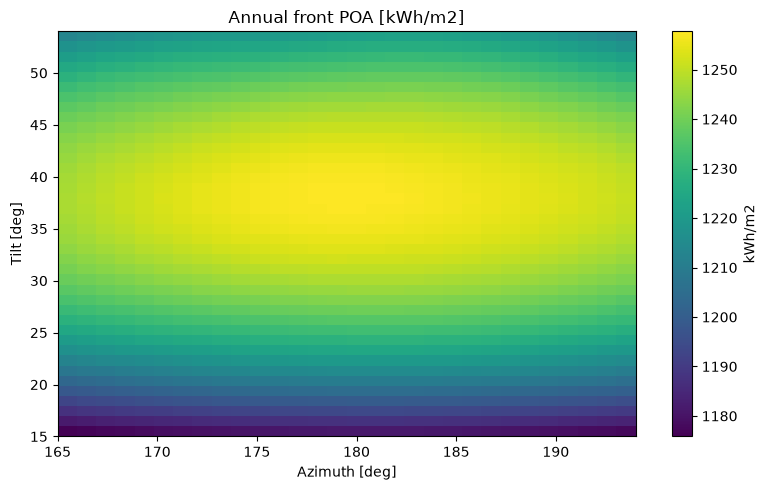

In [50]:
tilts = np.arange(15, 55, 1)
azimuths = np.arange(165, 195, 1)

rows = []
for tilt in tilts:
    for az in azimuths:
        annual = poa_annual_mono(tilt, az, weather, solar_zenith, solar_azimuth, dni_extra,albedo)
        rows.append({"tilt": tilt, "azimuth": az, "annual_kwh_m2": annual})

sweep_mono_flat = pd.DataFrame(rows)
best_flat = sweep_mono_flat.loc[sweep_mono_flat["annual_kwh_m2"].idxmax()]
print(best_flat)

pivot = sweep_mono_flat.pivot(index="tilt", columns="azimuth", values="annual_kwh_m2")
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(pivot.values, aspect="auto", origin="lower",
               extent=[azimuths.min(), azimuths.max(), tilts.min(), tilts.max()])
ax.set_xlabel("Azimuth [deg]")
ax.set_ylabel("Tilt [deg]")
ax.set_title("Annual front POA [kWh/m2]")
plt.colorbar(im, label="kWh/m2")
plt.tight_layout()

Optimal tilt and azimuth for a bifacial module

tilt               24.000000
azimuth           181.000000
annual_kwh_m2    1224.594567
Name: 286, dtype: float64


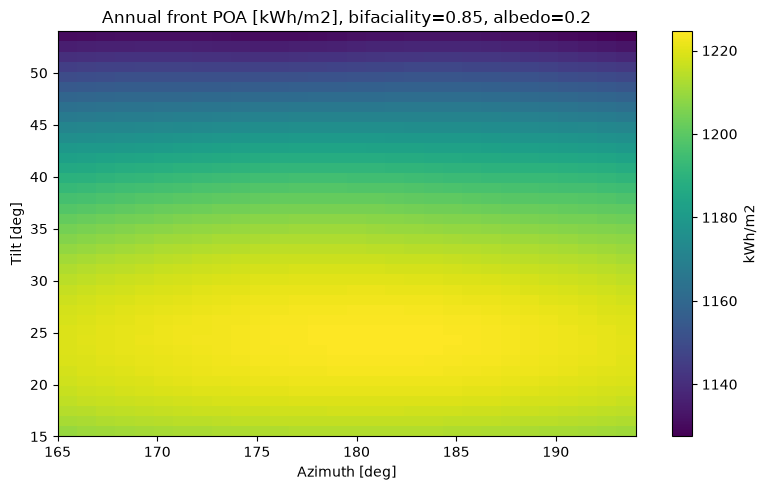

In [51]:
rows = []
for tilt in tilts:
    for az in azimuths:
        annual = poa_annual_bifacial(tilt, az, weather, solar_zenith, solar_azimuth,
                        height, gcr, pitch, albedo, module["bifaciality"], dni_extra)
        rows.append({"tilt": tilt, "azimuth": az, "annual_kwh_m2": annual})

sweep_bifacial = pd.DataFrame(rows)
best_bifacial = sweep_bifacial.loc[sweep_bifacial["annual_kwh_m2"].idxmax()]
print(best_bifacial)

pivot = sweep_bifacial.pivot(index="tilt", columns="azimuth", values="annual_kwh_m2")
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(pivot.values, aspect="auto", origin="lower",
               extent=[azimuths.min(), azimuths.max(), tilts.min(), tilts.max()])
ax.set_xlabel("Azimuth [deg]")
ax.set_ylabel("Tilt [deg]")
ax.set_title("Annual front POA [kWh/m2], bifaciality=0.85, albedo=0.2")
plt.colorbar(im, label="kWh/m2")
plt.tight_layout()

Recalculating yearly irradiance for the optimal tilt and azimuth

In [52]:
best_tilt = float(best_bifacial["tilt"])
best_az = float(best_bifacial["azimuth"])

poa_best = get_irradiance(
    surface_tilt=best_tilt,
    surface_azimuth=best_az,
    solar_zenith=solar_zenith,
    solar_azimuth=solar_azimuth,
    gcr=gcr,
    height=height,
    pitch=pitch,
    ghi=weather["ghi"],
    dhi=weather["dhi"],
    dni=weather["dni"],
    albedo=albedo,
    dni_extra=dni_extra,
    bifaciality=[module["bifaciality"]],
    model="perez",
)

effective_irradiance = poa_best["poa_global"].clip(lower=0)

String topology checks based on temperature-dependent voltage and current inverter limits

In [53]:
T_STC = 25.0
T_cold = weather["temp_air"].min()   # degC, from PVGIS weather

cell_temp = faiman(
    poa_global=effective_irradiance,
    temp_air=weather["temp_air"],
    wind_speed=weather["wind_speed"],
    u0=25.0,
    u1=6.84,
)

T_hot_cell = float(cell_temp.max()) # degC, using Faiman model


# number of modules
p_dc_target = inverter["pac0"] * ilr
n_modules_total = int(round(p_dc_target / module["pdc0"]))

# max string length constrained by inverter max voltage at cold temp
v_oc_cold = module["v_oc"] * (1 + module["beta_voc"] * (T_cold - T_STC))
n_s_max = int(inverter["v_dc_max"] // v_oc_cold)

# min string length constrained by mppt lower voltage bound at hot temp
v_mp_hot = module["v_mp"] * (1 + module["beta_voc"] * (T_hot_cell - T_STC))
n_s_min = int(-(-inverter["v_mppt_min"] // v_mp_hot))   # ceil division

n_s = n_s_max  # maximize string length to reduce n_p and balance mppt inputs

# sweep parallel strings and pick the ILR closest to target

max_strings_per_mppt_by_imp = int(inverter["i_mppt_max"] // module["i_mp"])
max_strings_per_mppt_by_isc = int(inverter["i_sc_mppt_max"] // module["i_sc"])
max_strings_per_mppt = min(max_strings_per_mppt_by_imp, max_strings_per_mppt_by_isc)
max_strings_per_mppt = min(max_strings_per_mppt, min(inverter["n_inputs_per_mppt"]))

p_string = n_s * module["pdc0"]  # DC power per string

best = None  # (abs_err, n_p, ilr_actual)
for n_p_cand in range(1, max_strings_per_mppt * inverter["n_mppt"] + 1):
    ilr_cand = n_p_cand * p_string / inverter["pac0"]
    err = abs(ilr_cand - ilr)
    if best is None or err < best[0]:
        best = (err, n_p_cand, ilr_cand)

_, n_p, ilr_actual = best

# distribute n_p across MPPTs, cap respected after remainder
strings_per_mppt = [min(max_strings_per_mppt, n_p // inverter["n_mppt"])] * inverter["n_mppt"]
remaining = n_p - sum(strings_per_mppt)
for i in range(remaining):
    strings_per_mppt[i] += 1

n_modules_actual = n_s * n_p
p_dc_actual = n_modules_actual * module["pdc0"]
ilr_actual = p_dc_actual / inverter["pac0"]

print(f"T_cold                : {T_cold:.1f} degC")
print(f"V_oc cold             : {v_oc_cold:.1f} V")
print(f"T_hot_cell            : {T_hot_cell:.1f} degC")
print(f"V_mp hot              : {v_mp_hot:.1f} V")
print(f"N_s range             : [{n_s_min}, {n_s_max}]")
print(f"N_s chosen            : {n_s}")
print(f"N_p total             : {n_p}")
print(f"Strings per MPPT      : {strings_per_mppt}")
print(f"Modules (actual)      : {n_modules_actual}")
print(f"DC capacity (actual)  : {p_dc_actual/1e6:.3f} MW")
print(f"ILR (actual)          : {ilr_actual:.3f}")

T_cold                : -7.5 degC
V_oc cold             : 54.9 V
T_hot_cell            : 57.9 degC
V_mp hot              : 38.7 V
N_s range             : [13, 27]
N_s chosen            : 27
N_p total             : 24
Strings per MPPT      : [4, 4, 4, 4, 4, 4]
Modules (actual)      : 648
DC capacity (actual)  : 0.434 MW
ILR (actual)          : 1.316


Set up module and inverter parameters for the ModelChain

In [54]:
cec_params = sdm.fit_cec_sam(
    celltype="monoSi",
    v_mp=module["v_mp"],
    i_mp=module["i_mp"],
    v_oc=module["v_oc"],
    i_sc=module["i_sc"],
    alpha_sc=module["alpha_isc"] * module["i_sc"],
    beta_voc=module["beta_voc"] * module["v_oc"],
    gamma_pmp=module["gamma_pdc"]*100,
    cells_in_series=module["cells_in_series"],
    temp_ref=25,
)
I_L_ref, I_o_ref, R_s, R_sh_ref, a_ref, Adjust = cec_params

module_parameters = {
    "alpha_sc": module["alpha_isc"] * module["i_sc"],        
    "I_L_ref": I_L_ref,
    "I_o_ref": I_o_ref,
    "R_sh_ref": R_sh_ref,
    "R_s": R_s,
    "Adjust": Adjust,
    "a_ref": a_ref,
    "N": module["cells_in_series"],
}

inverter_parameters = {
    "pdc0": inverter["pac0"] / inverter["eta_inv_nom"],  # based on pvwatts assumption
    "eta_inv_nom": inverter["eta_inv_nom"],
}

Calculate the ModelChain and plot DC/AC outputs

In [55]:
temperature_model_parameters = {"u0": 25.0, "u1": 6.84}

system = PVSystem(
    surface_tilt=best_tilt,
    surface_azimuth=best_az,
    module_parameters=module_parameters,
    inverter_parameters=inverter_parameters,
    temperature_model_parameters=temperature_model_parameters,
    modules_per_string=n_s,
    strings_per_inverter=n_p,
)

location = Location(lat, lon, tz="UTC")

mc = ModelChain(
    system, location,
    aoi_model="no_loss",
    spectral_model="no_loss",
    dc_model="cec",
    ac_model="pvwatts",
    temperature_model="faiman",
    losses_model="pvwatts",
    transposition_model="perez",
)

mc.run_model(weather)

dc = mc.results.dc["p_mp"].clip(lower=0)
ac = mc.results.ac["p_mp"].clip(lower=0)

p_dc_block = n_s * n_p * module["pdc0"]
n_inverters = max(1, int(round((ilr * inverter["pac0"]) / p_dc_block)))

ac_plant = n_inverters * ac
dc_plant = n_inverters * dc
clipped  = (dc_plant - ac_plant).clip(lower=0)

# i love plotly!
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=("Full year", "Zoom: 2023-06-15 to 2023-06-22"),
    shared_yaxes=True,
)

# Full year
fig.add_trace(go.Scatter(x=dc_plant.index, y=dc_plant, name="DC",
                         line=dict(width=0.6, color="#1f77b4")), row=1, col=1)
fig.add_trace(go.Scatter(x=ac_plant.index, y=ac_plant, name="AC",
                         line=dict(width=0.6, color="#ff7f0e")), row=1, col=1)
fig.add_trace(go.Scatter(x=dc_plant.index, y=[inverter["pac0"] * n_inverters] * len(dc_plant),
                         name="pac0 x N",
                         line=dict(width=0.6, color="black", dash="dash")), row=1, col=1)

# Zoom
z0, z1 = "2023-06-15", "2023-06-22"
fig.add_trace(go.Scatter(x=dc_plant.loc[z0:z1].index, y=dc_plant.loc[z0:z1], name="DC (zoom)",
                         line=dict(width=1.0, color="#1f77b4"), showlegend=False), row=1, col=2)
fig.add_trace(go.Scatter(x=ac_plant.loc[z0:z1].index, y=ac_plant.loc[z0:z1], name="AC (zoom)",
                         line=dict(width=1.0, color="#ff7f0e"), showlegend=False), row=1, col=2)
fig.add_trace(go.Scatter(x=dc_plant.loc[z0:z1].index,
                         y=[inverter["pac0"] * n_inverters] * len(dc_plant.loc[z0:z1]),
                         name="pac0 x N (zoom)",
                         line=dict(width=1.0, color="black", dash="dash"), showlegend=False), row=1, col=2)

fig.update_yaxes(title_text="Power [W]", row=1, col=1)
fig.update_xaxes(title_text="Time", row=1, col=1)
fig.update_xaxes(title_text="Time", row=1, col=2)
fig.update_layout(height=450, width=1400, hovermode="x unified", template="plotly_white",
                  title_text=f"Plant DC and AC output, {n_inverters} inverter blocks, ILR={ilr_actual:.2f}")
fig.show()

C:\Users\alexn\AppData\Roaming\Python\Python312\site-packages\scipy\optimize\_chandrupatla.py:437: RuntimeWarning: invalid value encountered in divide
  C = A / (A + B)


Check whether the apparently bad fit of the cec parameters means anything by comparing output to the simpler PVWatts model

In [56]:
# PVWatts module parameters
module_params_pvwatts = {
    "pdc0": module["pdc0"],
    "gamma_pdc": module["gamma_pdc"],
}

# PVWatts inverter parameters
inverter_parameters = {
    "pdc0": inverter["pac0"] / inverter["eta_inv_nom"],
    "eta_inv_nom": inverter["eta_inv_nom"],
}

# Faiman temperature model
temperature_model_parameters = {"u0": 25.0, "u1": 6.84}

system = PVSystem(
    surface_tilt=best_tilt,
    surface_azimuth=best_az,
    module_parameters=module_params_pvwatts,
    inverter_parameters=inverter_parameters,
    temperature_model_parameters=temperature_model_parameters,
    modules_per_string=n_s,
    strings_per_inverter=n_p,
)

location = Location(lat, lon, tz="UTC")

mc_pvwatts = ModelChain(
    system, location,
    aoi_model="no_loss",
    spectral_model="no_loss",
    dc_model="pvwatts",
    ac_model="pvwatts",
    temperature_model="faiman",
    losses_model="pvwatts",
    transposition_model="perez",
)

with np.errstate(invalid="ignore", divide="ignore"):
    mc_pvwatts.run_model(weather)

# One inverter block
dc_block = mc_pvwatts.results.dc.clip(lower=0)
ac_block = mc_pvwatts.results.ac.clip(lower=0)

# Scale to plant
p_dc_block = n_s * n_p * module["pdc0"]
n_inverters = max(1, int(round((ilr * inverter["pac0"]) / p_dc_block)))

dc_plant_pvwatts = n_inverters * dc_block
ac_plant_pvwatts = n_inverters * ac_block

cec_dc = dc_plant.copy()
cec_ac = ac_plant.copy()
pw_dc  = dc_plant_pvwatts.copy()
pw_ac  = ac_plant_pvwatts.copy()

summary = pd.DataFrame({
    "Model": ["CEC", "PVWatts"],
    "Annual DC [MWh]": [cec_dc.sum()/1e6, pw_dc.sum()/1e6],
    "Annual AC [MWh]": [cec_ac.sum()/1e6, pw_ac.sum()/1e6],
    "Clipped [MWh]": [
        (cec_dc - cec_ac).clip(lower=0).sum()/1e6,
        (pw_dc  - pw_ac ).clip(lower=0).sum()/1e6,
    ],
    "Max DC [MW]": [cec_dc.max()/1e6, pw_dc.max()/1e6],
    "Max AC [MW]": [cec_ac.max()/1e6, pw_ac.max()/1e6],
})
print(summary.round(2).to_string(index=False))

diff_ac = (cec_ac - pw_ac) / 1e3   # kW
z0, z1 = "2023-06-15", "2023-06-22"

fig = make_subplots(
    rows=3, cols=2,
    subplot_titles=(
        "Full year: AC output", "Zoom: AC output",
        "Full year: clipping (DC - AC)", "Zoom: clipping (DC - AC)",
        "Full year: CEC - PVWatts (AC)", "Zoom: CEC - PVWatts (AC)",
    ),
)

# Row 1: AC in kW
fig.add_trace(go.Scatter(x=cec_ac.index, y=cec_ac/1e3, name="CEC AC",
                         line=dict(width=0.5, color="#1f77b4")), row=1, col=1)
fig.add_trace(go.Scatter(x=pw_ac.index, y=pw_ac/1e3, name="PVWatts AC",
                         line=dict(width=0.5, color="#ff7f0e")), row=1, col=1)
fig.add_trace(go.Scatter(x=cec_ac.loc[z0:z1].index, y=cec_ac.loc[z0:z1]/1e3, name="CEC AC (zoom)",
                         line=dict(width=1.0, color="#1f77b4"), showlegend=False), row=1, col=2)
fig.add_trace(go.Scatter(x=pw_ac.loc[z0:z1].index, y=pw_ac.loc[z0:z1]/1e3, name="PVWatts AC (zoom)",
                         line=dict(width=1.0, color="#ff7f0e"), showlegend=False), row=1, col=2)

# Row 2: clipping in kW
cec_clip = (cec_dc - cec_ac).clip(lower=0) / 1e3
pw_clip  = (pw_dc  - pw_ac ).clip(lower=0) / 1e3
fig.add_trace(go.Scatter(x=cec_clip.index, y=cec_clip, name="CEC clipped",
                         fill="tozeroy", line=dict(width=0, color="rgba(31,119,180,0.4)")), row=2, col=1)
fig.add_trace(go.Scatter(x=pw_clip.index, y=pw_clip, name="PVWatts clipped",
                         fill="tozeroy", line=dict(width=0, color="rgba(255,127,14,0.4)")), row=2, col=1)
fig.add_trace(go.Scatter(x=cec_clip.loc[z0:z1].index, y=cec_clip.loc[z0:z1], name="CEC clipped (zoom)",
                         fill="tozeroy", line=dict(width=0, color="rgba(31,119,180,0.4)"), showlegend=False), row=2, col=2)
fig.add_trace(go.Scatter(x=pw_clip.loc[z0:z1].index, y=pw_clip.loc[z0:z1], name="PVWatts clipped (zoom)",
                         fill="tozeroy", line=dict(width=0, color="rgba(255,127,14,0.4)"), showlegend=False), row=2, col=2)

# Row 3: delta AC in kW
fig.add_trace(go.Scatter(x=diff_ac.index, y=diff_ac, name="CEC - PVWatts (AC)",
                         line=dict(width=0.5, color="#2ca02c")), row=3, col=1)
fig.add_hline(y=0, line=dict(color="black", width=0.6), row=3, col=1)
fig.add_trace(go.Scatter(x=diff_ac.loc[z0:z1].index, y=diff_ac.loc[z0:z1], name="CEC - PVWatts (AC, zoom)",
                         line=dict(width=1.0, color="#2ca02c"), showlegend=False), row=3, col=2)
fig.add_hline(y=0, line=dict(color="black", width=0.6), row=3, col=2)

for c in range(1, 3):
    fig.update_yaxes(title_text="AC [kW]", row=1, col=c)
    fig.update_yaxes(title_text="Clipped [kW]", row=2, col=c)
    fig.update_yaxes(title_text="Delta AC [kW]", row=3, col=c)
    fig.update_xaxes(title_text="Time", row=3, col=c)

fig.update_layout(height=900, width=1400, hovermode="x unified",
                  template="plotly_white",
                  title_text=f"CEC vs PVWatts, {n_inverters} inverter, ILR={ilr_actual:.2f}")
fig.show()

  Model  Annual DC [MWh]  Annual AC [MWh]  Clipped [MWh]  Max DC [MW]  Max AC [MW]
    CEC           461.57           450.25          11.32         0.38         0.33
PVWatts           458.24           446.97          11.28         0.39         0.33


In [57]:
print(f"PVWatts DC block max:  {dc_block.max():.0f} W")
print(f"CEC DC block max:      {dc.max():.0f} W")   # if you kept it
print(f"Inverter pdc0:         {inverter_parameters['pdc0']:.0f} W")
print(f"Inverter pac0:         {inverter['pac0']:.0f} W")
print(f"Threshold to clip:     {inverter_parameters['pdc0'] * inverter['eta_inv_nom']:.0f} W AC")

PVWatts DC block max:  385444 W
CEC DC block max:      384383 W
Inverter pdc0:         334008 W
Inverter pac0:         330000 W
Threshold to clip:     330000 W AC


In [58]:
# Per-kW_AC normalized AC generation
ac_cec_per_kwac = ac_plant / (n_inverters * inverter["pac0"])
ac_pw_per_kwac  = ac_plant_pvwatts / (n_inverters * inverter["pac0"])

print(f"CEC     max AC/kWac: {ac_cec_per_kwac.max():.4f}")
print(f"PVWatts max AC/kWac: {ac_pw_per_kwac.max():.4f}")

z0, z1 = "2023-06-15", "2023-06-22"

fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        "Full year: AC per kWac",
        "Zoom: AC per kWac",
        "Full year: CEC - PVWatts",
        "Zoom: CEC - PVWatts",
    ),
    shared_yaxes=False,
)

fig.add_trace(go.Scatter(x=ac_cec_per_kwac.index, y=ac_cec_per_kwac, name="CEC",
                         line=dict(width=0.5, color="#1f77b4")), row=1, col=1)
fig.add_trace(go.Scatter(x=ac_pw_per_kwac.index, y=ac_pw_per_kwac, name="PVWatts",
                         line=dict(width=0.5, color="#ff7f0e")), row=1, col=1)
fig.add_trace(go.Scatter(x=ac_cec_per_kwac.loc[z0:z1].index, y=ac_cec_per_kwac.loc[z0:z1],
                         name="CEC (zoom)", line=dict(width=1.0, color="#1f77b4"), showlegend=False), row=1, col=2)
fig.add_trace(go.Scatter(x=ac_pw_per_kwac.loc[z0:z1].index, y=ac_pw_per_kwac.loc[z0:z1],
                         name="PVWatts (zoom)", line=dict(width=1.0, color="#ff7f0e"), showlegend=False), row=1, col=2)

diff = ac_cec_per_kwac - ac_pw_per_kwac
fig.add_trace(go.Scatter(x=diff.index, y=diff, name="CEC - PVWatts",
                         line=dict(width=0.5, color="#2ca02c")), row=2, col=1)
fig.add_hline(y=0, line=dict(color="black", width=0.6), row=2, col=1)
fig.add_trace(go.Scatter(x=diff.loc[z0:z1].index, y=diff.loc[z0:z1], name="CEC - PVWatts (zoom)",
                         line=dict(width=1.0, color="#2ca02c"), showlegend=False), row=2, col=2)
fig.add_hline(y=0, line=dict(color="black", width=0.6), row=2, col=2)

for c in range(1, 3):
    fig.update_yaxes(title_text="AC / kWac", row=1, col=c)
    fig.update_yaxes(title_text="Delta AC / kWac", row=2, col=c)
    fig.update_xaxes(title_text="Time", row=2, col=c)

fig.update_layout(height=700, width=1400, hovermode="x unified",
                  template="plotly_white",
                  title_text="Per-kWac generation profile, CEC vs PVWatts")
fig.show()

CEC     max AC/kWac: 1.0000
PVWatts max AC/kWac: 1.0000


In [59]:
flh_cec = ac_plant.sum() / (n_inverters * inverter["pac0"])
flh_pw  = ac_plant_pvwatts.sum() / (n_inverters * inverter["pac0"])

print(f"CEC     equivalent full-load hours: {flh_cec:.0f} h/year")
print(f"PVWatts equivalent full-load hours: {flh_pw:.0f} h/year")
print(f"Delta: {(flh_cec - flh_pw):+.1f} h/year")

CEC     equivalent full-load hours: 1364 h/year
PVWatts equivalent full-load hours: 1354 h/year
Delta: +9.9 h/year
